### Recovering the symbol from a travelling fKdV waves

In [19]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

In [20]:
from solvers.spectral import fKdVNewton
from solvers.pde import fKdV
from solvers.lsm import LSM
from solvers.help import *

from waves.waveGen import fKdVPacket

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [21]:
P           = 4* np.pi
amps = np.linspace(0.1,1,5)
means = np.zeros_like(amps)

N           = 2**6
alpha = 2

dt = 5e-3
T = 3

In [22]:
x = np.linspace(0,P,N)

In [23]:
kdvp = fKdVPacket(P=P,N=N,amp_list=amps, mean_list=means, dt = dt, T= T, alpha=2)
H = kdvp.mainloop()

In [24]:
lsm = LSM(eta_list=H, dt = dt, P = P)
X = lsm.lsm()

In [25]:
ell, n = lsm.fit_symbol()
print(fit_table(ell,n,part='real'))


          ξ^3       ξ^2       ξ^1        ξ^0
ell  0.000304  0.070527 -0.034187 -12.721996
n   -0.000029 -0.002336  0.002791   0.408860


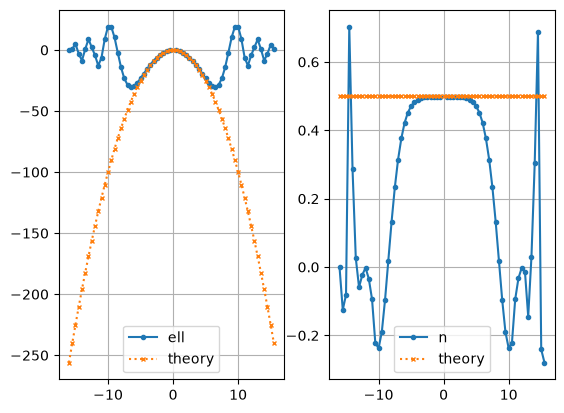

In [26]:
f = fKdV(P=P,dt=dt,T=T,u0 = H[0][0], alpha=alpha)
lsm.plot_symbol_fit(ell_t=f.dispersion)